# Explorative Datenanalyse: `rfd_main_cleaned.csv` (Referenzdatensatz)

Dieses Notebook führt dieselbe schrittweise explorative Analyse wie
`EDA_Datenexploration.ipynb` durch, diesmal jedoch für die von der ursprünglichen
Kaggle-Quelle vorbereinigte Referenzversion `rfd_main_cleaned.csv` (vgl. Abschnitt 3.2,
Vergleichsrahmen und Rolle des Referenzdatensatzes). Ziel ist der direkte Vergleich:
Welche der vier untersuchten Fehlerarten wurden in dieser Referenzversion bereits
behoben, und welche nicht?

**Ablauf (identisch zum Rohdatensatz-Notebook):**
1. Import und Laden der Daten
2. Grundlegende Struktur (Zeilen, Spalten, Datentypen)
3. Fehlende Werte
4. Duplikate
5. Numerische Spalten (Deskriptivstatistik, Ausreißer)
6. Kategoriale Spalten (parent_category, thread_category, source)
7. Formatierungsfehler (price, saving) -- Kontrolle des Bereinigungsstands
8. Semantische Heterogenität (thread_category vs. parent_category)
9. Zeitspalten (creation_date, expiry, last_reply)
10. Textspalte (title)
11. Zusammenfassung und Vergleich mit dem Rohdatensatz


## 1. Import und Laden der Daten

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

df = pd.read_csv("rfd_main_cleaned.csv")
print(f"Datensatz geladen: {df.shape[0]} Zeilen, {df.shape[1]} Spalten")


Datensatz geladen: 1325 Zeilen, 15 Spalten


## 2. Grundlegende Struktur

### 2.1 Anzahl Zeilen und Spalten

In [2]:
n_rows, n_cols = df.shape
print(f"Zeilen (Datensätze):  {n_rows}")
print(f"Spalten (Attribute):  {n_cols}")
print()
print("Spaltennamen:")
for i, c in enumerate(df.columns, 1):
    print(f"  {i:2d}. {c}")


Zeilen (Datensätze):  1325
Spalten (Attribute):  15

Spaltennamen:
   1. Unnamed: 0
   2. author
   3. creation_date
   4. expiry
   5. last_reply
   6. parent_category
   7. price
   8. replies
   9. saving
  10. source
  11. thread_category
  12. title
  13. url
  14. views
  15. votes


### 2.2 Vorschau der ersten und letzten Zeilen

In [3]:
df.head(5)

,Unnamed: 0,author,creation_date,expiry,last_reply,parent_category,price,replies,saving,source,thread_category,title,url,views,votes
0,0,flora0222,2020-07-16 08:29:00,NaN,2020-07-17 09:20:00,NaN,6.99,89,NaN,Staples,Home & Garden,"One Step Hand Sanitizer, Fragrance-Free, 473mL...",https://staplescanada.4u8mqw.net/c/341376/7554...,15445,132
1,1,yellowmp5,2020-07-13 13:29:00,NaN,2020-07-17 09:18:00,NaN,NaN,441,NaN,Home Depot,Home & Garden,RYOBI 20% coupon barcode,NaN,59219,159
2,2,riseagainstthemachine,2020-07-02 10:03:00,NaN,2020-07-17 09:17:00,NaN,NaN,92,NaN,Kits,Apparel,Kits.com Free Pair Prescription Glasses,https://www.kits.com/freeglasses.html,25242,54
3,3,Googliya,2020-07-17 07:23:00,NaN,2020-07-17 09:15:00,NaN,469.99,13,NaN,Costco,Sports & Fitness,"Northrock xc00, fat Tire bike, $469.99",https://www.costco.ca/northrock-xc00-fat-tire-...,1769,2
4,4,Presents,2020-07-16 13:36:00,2020-07-29 00:00:00,2020-07-17 09:15:00,NaN,NaN,24,NaN,Canadian Tire,Automotive,60x total CT Money when you pay with your Tria...,NaN,2981,9


In [4]:
df.tail(5)

,Unnamed: 0,author,creation_date,expiry,last_reply,parent_category,price,replies,saving,source,thread_category,title,url,views,votes
1320,1321,zobi123,2020-06-24 17:46:00,NaN,2020-06-25 14:39:00,Automotive,112.00,20,NaN,Amazon.ca,Auto Parts & Accessories,Noco Portable Jump Starter $112,http://www.amazon.ca/gp/redirect.html?ie=UTF8&...,3729,8
1321,1322,alextch,2020-06-22 16:43:00,NaN,2020-06-25 14:06:00,Sports & Fitness,599.99,54,NaN,Costco,Equipment,Marcy Cage Home Gym System $599.99,https://www.costco.ca/marcy-cage-home-gym-syst...,14865,22
1322,1323,MichaelT26086,2020-06-13 13:18:00,2020-09-01 00:00:00,2020-06-13 18:38:00,NaN,NaN,2,0.50000,Redirectingat,Apparel,North Face Healthcare Workers 50% Discount on ...,http://go.redirectingat.com?id=2927x594702&amp...,3772,7
1323,1324,Minimo07,2020-04-21 14:36:00,2020-05-03 00:00:00,2020-04-22 22:58:00,NaN,19.99,27,0.20008,NaN,Groceries,Charmin Ultra Soft Bathroom Tissue 30 rolls $1...,NaN,4296,0
1324,1325,hongsj,2019-12-25 03:44:00,NaN,2019-12-25 15:00:00,Computers & Electronics,NaN,3,NaN,Google,Cell Phones,"[Google] Pixel 4,4XL -200 3a,3aXL -150",https://store.google.com/ca/collection/offers,6382,0


### 2.3 Datentypen je Spalte

In [5]:
dtype_overview = pd.DataFrame({
    "Spalte": df.columns,
    "Pandas-Dtype": df.dtypes.astype(str).values,
    "Nicht-null (n)": df.notna().sum().values,
    "Nicht-null (%)": (df.notna().mean().values * 100).round(1),
    "Eindeutige Werte": [df[c].nunique() for c in df.columns],
})
dtype_overview


,Spalte,Pandas-Dtype,Nicht-null (n),Nicht-null (%),Eindeutige Werte
0,Unnamed: 0,int64,1325,100.0,1325
1,author,object,1325,100.0,945
2,creation_date,object,1325,100.0,1282
3,expiry,object,370,27.9,73
4,last_reply,object,1325,100.0,1252
5,parent_category,object,825,62.3,12
6,price,float64,1084,81.8,536
7,replies,int64,1325,100.0,209
8,saving,float64,511,38.6,222
9,source,object,1262,95.2,280


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1325 entries, 0 to 1324
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       1325 non-null   int64  
 1   author           1325 non-null   object 
 2   creation_date    1325 non-null   object 
 3   expiry           370 non-null    object 
 4   last_reply       1325 non-null   object 
 5   parent_category  825 non-null    object 
 6   price            1084 non-null   float64
 7   replies          1325 non-null   int64  
 8   saving           511 non-null    float64
 9   source           1262 non-null   object 
 10  thread_category  1325 non-null   object 
 11  title            1325 non-null   object 
 12  url              1044 non-null   object 
 13  views            1325 non-null   int64  
 14  votes            1325 non-null   int64  
dtypes: float64(2), int64(4), object(9)
memory usage: 155.4+ KB


**Beobachtung:** Im Unterschied zum Rohdatensatz sind `price` und `saving` hier
bereits als `float64` (nicht mehr `object`) codiert -- ein erster Beleg dafür, dass
die Formatierungsfehler dieser beiden Spalten in der Referenzversion tatsächlich
behoben wurden. `creation_date`, `expiry` und `last_reply` bleiben dagegen `object`,
liegen aber -- wie Abschnitt 9 zeigt -- bereits in einem einheitlichen ISO-ähnlichen
Format vor.

## 3. Fehlende Werte

### 3.1 Fehlende Werte je Spalte (absolut und relativ)

In [7]:
missing = pd.DataFrame({
    "fehlend (n)": df.isna().sum(),
    "fehlend (%)": (df.isna().mean() * 100).round(1),
}).sort_values("fehlend (%)", ascending=False)
missing = missing[missing["fehlend (n)"] > 0]
missing


,fehlend (n),fehlend (%)
expiry,955,72.1
saving,814,61.4
parent_category,500,37.7
url,281,21.2
price,241,18.2
source,63,4.8


### 3.2 Visualisierung: Anteil fehlender Werte je Spalte

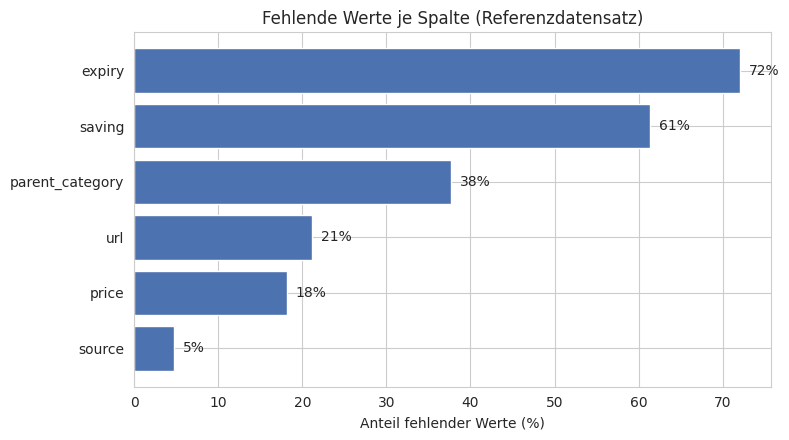

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
missing_sorted = missing.sort_values("fehlend (%)")
ax.barh(missing_sorted.index, missing_sorted["fehlend (%)"], color="#4C72B0")
ax.set_xlabel("Anteil fehlender Werte (%)")
ax.set_title("Fehlende Werte je Spalte (Referenzdatensatz)")
for i, v in enumerate(missing_sorted["fehlend (%)"]):
    ax.text(v + 1, i, f"{v:.0f}%", va="center")
plt.tight_layout()
plt.show()


### 3.3 Heatmap der fehlenden Werte

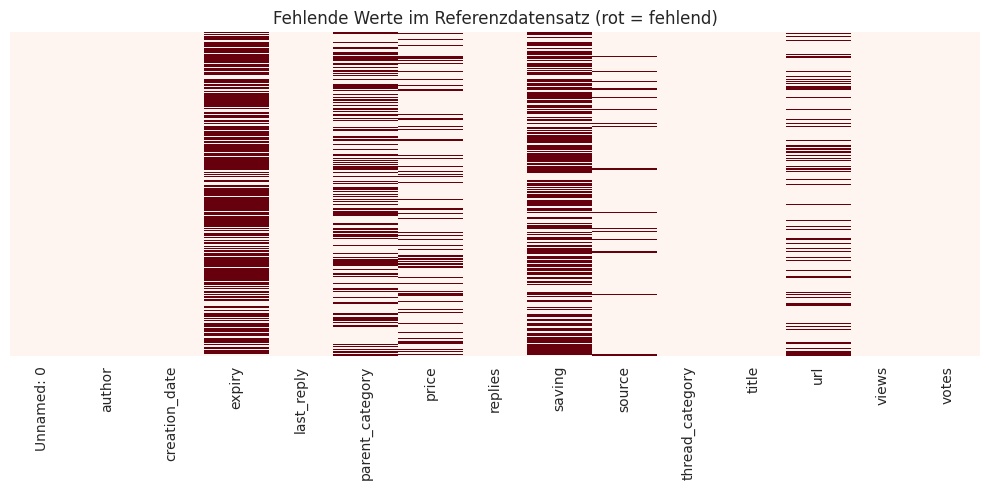

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap="Reds", ax=ax)
ax.set_title("Fehlende Werte im Referenzdatensatz (rot = fehlend)")
plt.tight_layout()
plt.show()


### 3.4 Zusammenhang zwischen fehlenden Feldern (Ko-Auftreten)

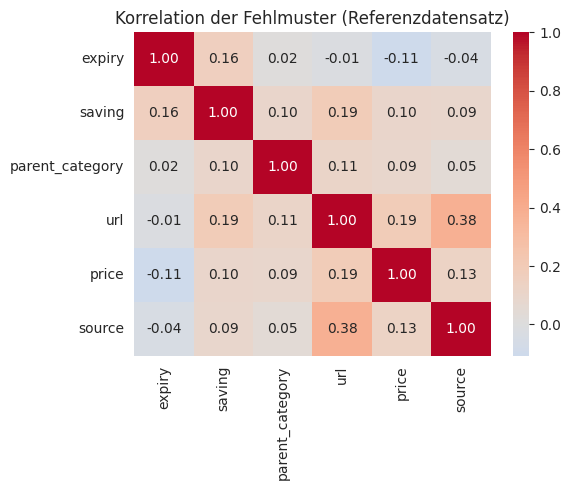

In [10]:
miss_cols = missing.index.tolist()
co_missing = df[miss_cols].isna().astype(int).corr()
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(co_missing, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Korrelation der Fehlmuster (Referenzdatensatz)")
plt.tight_layout()
plt.show()


## 4. Duplikate

### 4.1 Vollständig identische Zeilen

In [11]:
n_exact_dupes = df.duplicated(keep=False).sum()
print(f"Vollständig identische Zeilen: {n_exact_dupes}")


Vollständig identische Zeilen: 0


### 4.2 Duplikate nach einzelnen Schlüsselspalten

In [12]:
dup_checks = {
    "identischer Titel (title)": df.duplicated(subset=["title"], keep=False).sum(),
    "identische URL (url, ohne NaN)": df[df["url"].notna()].duplicated(subset=["url"], keep=False).sum(),
    "identischer Autor + Titel": df.duplicated(subset=["author", "title"], keep=False).sum(),
    "identischer Autor + Preis + Kategorie": df.duplicated(subset=["author", "price", "parent_category"], keep=False).sum(),
}
pd.DataFrame.from_dict(dup_checks, orient="index", columns=["Anzahl betroffener Zeilen"])


,Anzahl betroffener Zeilen
identischer Titel (title),34
"identische URL (url, ohne NaN)",50
identischer Autor + Titel,32
identischer Autor + Preis + Kategorie,89


### 4.3 Beispiele: Zeilen mit identischer URL

In [13]:
url_dupes = df[df["url"].notna() & df.duplicated(subset=["url"], keep=False)].sort_values("url")
url_dupes[["title", "author", "creation_date", "price", "url"]].head(10)


,title,author,creation_date,price,url
23,Clarisonic - Shutting Down Sale - 50% Off Ever...,laughingoh,2020-07-14 23:24:00,NaN,http://clarisonicca.sjv.io/c/341376/344610/512...
29,Clarisonic - Shutting Down Sale - 50% Off Ever...,laughingoh,2020-07-14 23:24:00,NaN,http://clarisonicca.sjv.io/c/341376/344610/512...
1295,End of season sale - 50% off | GETEXTRA,michelangelo88,2020-06-23 10:33:00,NaN,http://reebok-canada.sjv.io/c/341376/356400/52...
532,"40% off outlet, 30% off select items Summer Sale",iced~metal,2020-07-11 05:08:00,NaN,http://reebok-canada.sjv.io/c/341376/356400/52...
61,"AirHeads Bars, Chewy Fruit Candy, Variety Pack...",Stevebos,2020-07-17 05:30:00,7.46,http://www.amazon.ca/gp/redirect.html?ie=UTF8&...
60,"AirHeads Bars, 60 Count 7.46$ Lowest Camelprice",Stevebos,2020-07-17 05:31:00,7.46,http://www.amazon.ca/gp/redirect.html?ie=UTF8&...
24,Bodum Bistro Double Wall 0.45l Set of 2 Coffee...,mikebmt,2020-07-16 23:23:00,30.00,http://www.amazon.ca/gp/redirect.html?ie=UTF8&...
30,Bodum Bistro Double Wall 0.45l Set of 2 Coffee...,mikebmt,2020-07-16 23:23:00,30.00,http://www.amazon.ca/gp/redirect.html?ie=UTF8&...
417,A2 LENRUE Portable Wireless Bluetooth Speaker ...,Terabithia,2020-07-13 21:49:00,23.99,http://www.amazon.ca/gp/redirect.html?ie=UTF8&...
418,A2 LENRUE Portable Wireless Bluetooth Speaker ...,Terabithia,2020-07-13 21:49:00,23.99,http://www.amazon.ca/gp/redirect.html?ie=UTF8&...


**Beobachtung:** Die Anzahl der URL-Duplikate ist -- wie in Abschnitt 3.2 der
Arbeit beschrieben -- im Referenzdatensatz praktisch unverändert gegenüber dem
Rohdatensatz: Duplikate wurden hier nicht bereinigt.

## 5. Numerische Spalten: Deskriptivstatistik und Ausreißer

### 5.1 Deskriptive Statistik

In [14]:
numeric_cols = ["views", "votes", "replies", "price", "saving"]
df[numeric_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
views,1325.0,13744.623396,33823.081978,127.0,2194.00,4212.00,11149.00,507393.0
votes,1325.0,12.825660,28.032361,-73.0,1.00,5.00,14.00,319.0
replies,1325.0,52.933585,144.409555,0.0,5.00,15.00,45.00,2791.0
price,1084.0,190.698635,360.760773,0.0,17.99,59.99,198.25,4499.0
saving,511.0,0.413187,0.225004,0.0,0.24,0.40,0.50,1.0


### 5.2 Verteilungen (Histogramme)

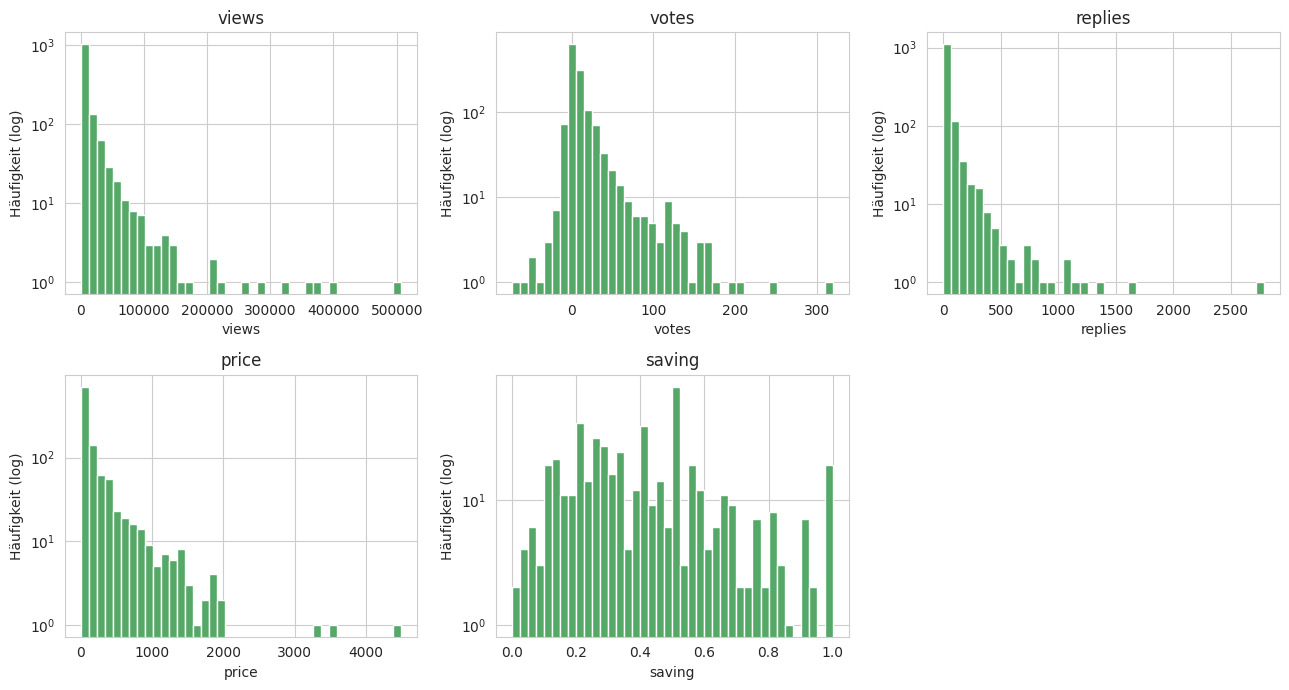

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
axes = axes.flatten()
for ax, col in zip(axes, numeric_cols):
    ax.hist(df[col].dropna(), bins=40, color="#55A868")
    ax.set_title(col)
    ax.set_yscale("log")
    ax.set_xlabel(col)
    ax.set_ylabel("Häufigkeit (log)")
axes[-1].axis("off")
plt.tight_layout()
plt.show()


### 5.3 Ausreißer via IQR-Regel

In [16]:
outlier_summary = {}
for col in numeric_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary[col] = {"Q1": q1, "Q3": q3, "IQR": iqr, "untere Grenze": lower, "obere Grenze": upper, "Ausreißer (n)": n_out}
pd.DataFrame(outlier_summary).T


,Q1,Q3,IQR,untere Grenze,obere Grenze,Ausreißer (n)
views,2194.00,11149.00,8955.00,-11238.50,24581.50,171.0
votes,1.00,14.00,13.00,-18.50,33.50,146.0
replies,5.00,45.00,40.00,-55.00,105.00,143.0
price,17.99,198.25,180.26,-252.40,468.64,117.0
saving,0.24,0.50,0.26,-0.15,0.89,28.0


### 5.4 Plausibilitätsprüfung: negative oder unmögliche Werte

In [17]:
checks = {
    "price < 0": (df["price"] < 0).sum(),
    "saving < 0": (df["saving"] < 0).sum(),
    "saving > 1 (>100% Rabatt)": (df["saving"] > 1).sum(),
    "views < votes": (df["views"] < df["votes"]).sum(),
}
pd.Series(checks, name="Anzahl betroffener Zeilen")


price < 0                    0
saving < 0                   0
saving > 1 (>100% Rabatt)    0
views < votes                0
Name: Anzahl betroffener Zeilen, dtype: int64

## 6. Kategoriale Spalten

### 6.1 `parent_category` (grobe Kategorie)

In [18]:
print(f"Eindeutige Werte: {df['parent_category'].nunique()}")
df["parent_category"].value_counts(dropna=False)


Eindeutige Werte: 12


parent_category
NaN                        500
Computers & Electronics    339
Home & Garden              207
Entertainment               43
Financial Services          35
Sports & Fitness            33
Beauty & Wellness           32
Automotive                  31
Restaurants                 29
Kids & Babies               26
Apparel                     25
Travel                      14
Small Business              11
Name: count, dtype: int64

### 6.2 `thread_category` (feingranulare Kategorie)

In [19]:
print(f"Eindeutige Werte: {df['thread_category'].nunique()}")
df["thread_category"].value_counts(dropna=False).head(20)


Eindeutige Werte: 55


thread_category
Computers & Electronics            176
Other                               93
Home Improvement & Tools            89
Home & Garden                       84
Groceries                           77
Video Games                         77
Peripherals & Accessories           65
Appliances                          53
Apparel                             47
Computers & Tablets/eReaders        47
Home Theatre & Audio                40
Cell Phones                         35
Books, Music, Movies, Magazines     34
Sports & Fitness                    28
Beauty Supplies & Personal Care     26
Automotive                          23
Televisions                         21
Beauty & Wellness                   20
Outdoors & Patio                    19
Auto Parts & Accessories            19
Name: count, dtype: int64

### 6.3 `source` (Händler/Anbieter)

In [20]:
print(f"Eindeutige Werte: {df['source'].nunique()}")
df["source"].value_counts(dropna=False).head(15)


Eindeutige Werte: 280


source
Amazon.ca              215
Costco                 126
Home Depot              64
NaN                     63
Walmart                 59
Canadian Tire           46
Best Buy                44
Princess Auto           27
Dollarama               24
Staples                 24
Amazon                  24
Visions Electronics     15
Redirectingat           14
Linksynergy             13
Microsoft Store         12
Name: count, dtype: int64

### 6.4 Visualisierung: Top-Kategorien

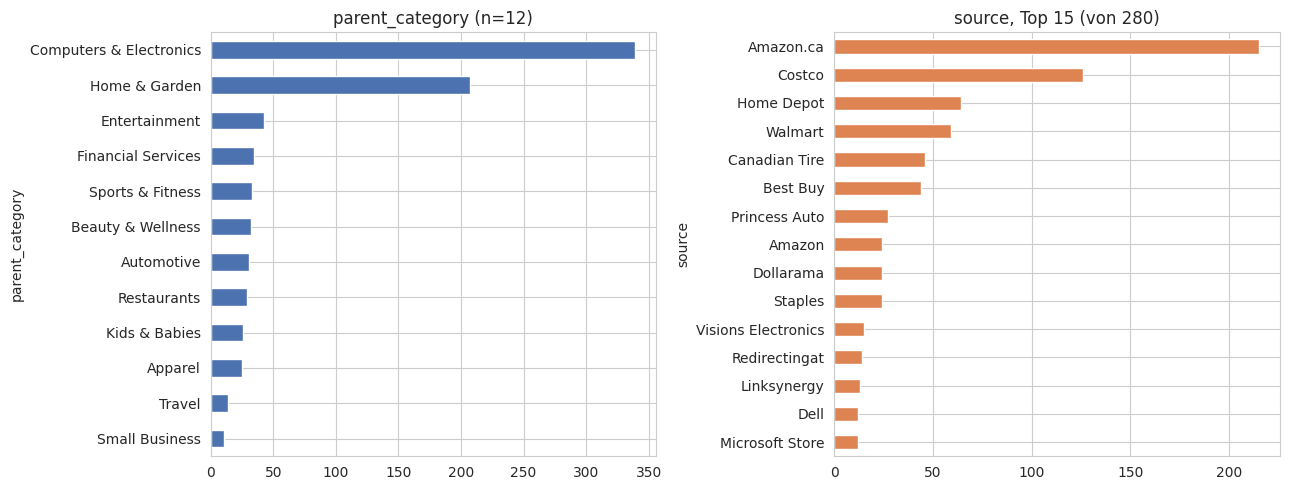

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
df["parent_category"].value_counts().plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_title("parent_category (n=" + str(df["parent_category"].nunique()) + ")")
axes[0].invert_yaxis()

top_source = df["source"].value_counts().head(15)
top_source.plot(kind="barh", ax=axes[1], color="#DD8452")
axes[1].set_title("source, Top 15 (von " + str(df["source"].nunique()) + ")")
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()


## 7. Formatierungsfehler: `price` und `saving` -- Kontrolle des Bereinigungsstands

Anders als im Rohdatensatz-Notebook ist hier keine Formatmuster-Klassifikation
per Regex mehr nötig, da `price` und `saving` bereits als numerische Spalten
vorliegen. Stattdessen wird geprüft, ob die Bereinigung vollständig und plausibel
ist.

### 7.1 Sind alle Werte tatsächlich rein numerisch?

In [22]:
print("price ist vollständig numerisch:", pd.api.types.is_numeric_dtype(df["price"]))
print("saving ist vollständig numerisch:", pd.api.types.is_numeric_dtype(df["saving"]))
print()
print("price -- Wertebereich:", df["price"].min(), "bis", df["price"].max())
print("saving -- Wertebereich:", df["saving"].min(), "bis", df["saving"].max())


price ist vollständig numerisch: True
saving ist vollständig numerisch: True

price -- Wertebereich: 0.0 bis 4499.0
saving -- Wertebereich: 0.0 bis 1.0


### 7.2 Verteilung von price und saving nach Bereinigung

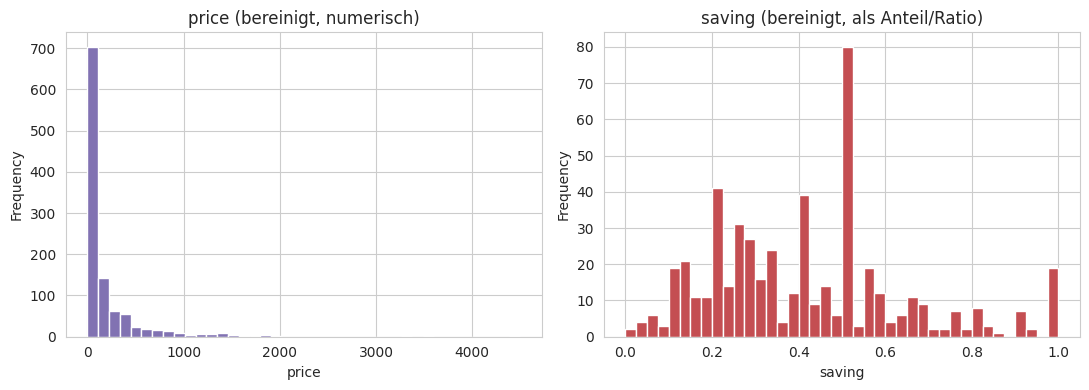

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df["price"].dropna().plot(kind="hist", bins=40, ax=axes[0], color="#8172B2")
axes[0].set_title("price (bereinigt, numerisch)")
axes[0].set_xlabel("price")

df["saving"].dropna().plot(kind="hist", bins=40, ax=axes[1], color="#C44E52")
axes[1].set_title("saving (bereinigt, als Anteil/Ratio)")
axes[1].set_xlabel("saving")
plt.tight_layout()
plt.show()


### 7.3 Fehlende Werte trotz Bereinigung

In [24]:
print(f"price weiterhin fehlend:  {df['price'].isna().sum()} von {len(df)} ({df['price'].isna().mean()*100:.1f}%)")
print(f"saving weiterhin fehlend: {df['saving'].isna().sum()} von {len(df)} ({df['saving'].isna().mean()*100:.1f}%)")


price weiterhin fehlend:  241 von 1325 (18.2%)
saving weiterhin fehlend: 814 von 1325 (61.4%)


**Beobachtung:** Die Formatierung von `price` und `saving` wurde im
Referenzdatensatz vollständig vereinheitlicht (beide Spalten sind jetzt rein
numerisch, keine Restformate wie `$`, `%` oder `off` mehr sichtbar). Die
*Vollständigkeit* wurde dabei jedoch nicht verbessert -- `saving` fehlt hier sogar
anteilig noch etwas häufiger als im Rohdatensatz (vgl. Abschnitt 3.2 der Arbeit).

## 8. Semantische Heterogenität: `thread_category` vs. `parent_category`

### 8.1 Wie viele thread_category-Werte sind mehrdeutig?

In [25]:
both = df[df["thread_category"].notna() & df["parent_category"].notna()]
mapping_counts = both.groupby("thread_category")["parent_category"].nunique().sort_values(ascending=False)
print(f"thread_category-Werte insgesamt (mit bekannter parent_category): {mapping_counts.shape[0]}")
print(f"davon mehrdeutig (>1 parent_category): {(mapping_counts > 1).sum()}")
mapping_counts[mapping_counts > 1]


thread_category-Werte insgesamt (mit bekannter parent_category): 42
davon mehrdeutig (>1 parent_category): 1


thread_category
Other    10
Name: parent_category, dtype: int64

### 8.2 Kreuztabelle (Ausschnitt)

In [26]:
ct = pd.crosstab(both["thread_category"], both["parent_category"])
ct.loc[ct.sum(axis=1).sort_values(ascending=False).index].head(15)


parent_category,Apparel,Automotive,Beauty & Wellness,Computers & Electronics,Entertainment,Financial Services,Home & Garden,Kids & Babies,Restaurants,Small Business,Sports & Fitness,Travel
thread_category,,,,,,,,,,,,
Other,0,12,6,24,6,2,24,2,3,0,9,5
Home Improvement & Tools,0,0,0,0,0,0,89,0,0,0,0,0
Video Games,0,0,0,77,0,0,0,0,0,0,0,0
Peripherals & Accessories,0,0,0,65,0,0,0,0,0,0,0,0
Appliances,0,0,0,0,0,0,53,0,0,0,0,0
Computers & Tablets/eReaders,0,0,0,47,0,0,0,0,0,0,0,0
Home Theatre & Audio,0,0,0,40,0,0,0,0,0,0,0,0
Cell Phones,0,0,0,35,0,0,0,0,0,0,0,0
"Books, Music, Movies, Magazines",0,0,0,0,34,0,0,0,0,0,0,0


**Beobachtung:** Anzahl und Struktur der `thread_category`/`parent_category`-Werte
sind gegenüber dem Rohdatensatz praktisch unverändert -- eine Taxonomie-Harmonisierung
wurde in der Referenzversion nicht vorgenommen (vgl. Abschnitt 3.2).

## 9. Zeitspalten

### 9.1 Parsing und Wertebereich

In [27]:
for col in ["creation_date", "expiry", "last_reply"]:
    parsed = pd.to_datetime(df[col], errors="coerce")
    n_failed = df[col].notna().sum() - parsed.notna().sum()
    print(f"{col:15s}: {parsed.min()}  bis  {parsed.max()}   (nicht parsebar: {n_failed})")


creation_date  : 2018-02-16 13:20:00  bis  2020-07-17 08:06:00   (nicht parsebar: 0)
expiry         : 2020-03-01 00:00:00  bis  2021-01-01 00:00:00   (nicht parsebar: 0)
last_reply     : 2019-12-25 15:00:00  bis  2020-07-17 09:37:00   (nicht parsebar: 0)


### 9.2 Zeitliche Verteilung der Postings

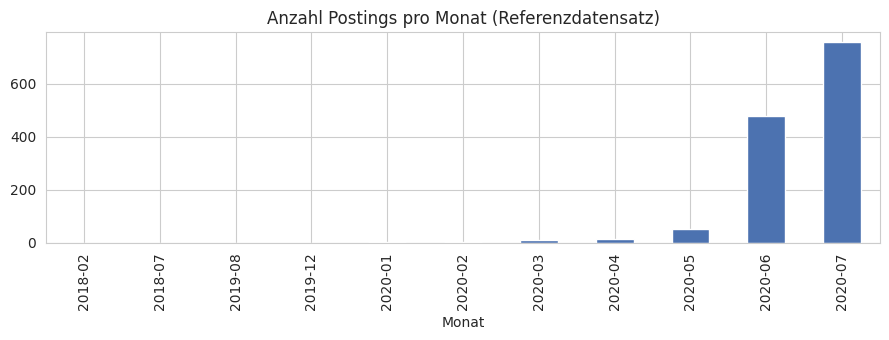

In [28]:
creation = pd.to_datetime(df["creation_date"], errors="coerce")
fig, ax = plt.subplots(figsize=(9,3.5))
creation.dt.to_period("M").value_counts().sort_index().plot(kind="bar", ax=ax, color="#4C72B0")
ax.set_title("Anzahl Postings pro Monat (Referenzdatensatz)")
ax.set_xlabel("Monat")
plt.tight_layout()
plt.show()


## 10. Textspalte: `title`

### 10.1 Längenverteilung

count    1325.000000
mean       56.911698
std        22.263674
min         3.000000
25%        40.000000
50%        53.000000
75%        70.000000
max       120.000000
Name: title, dtype: float64


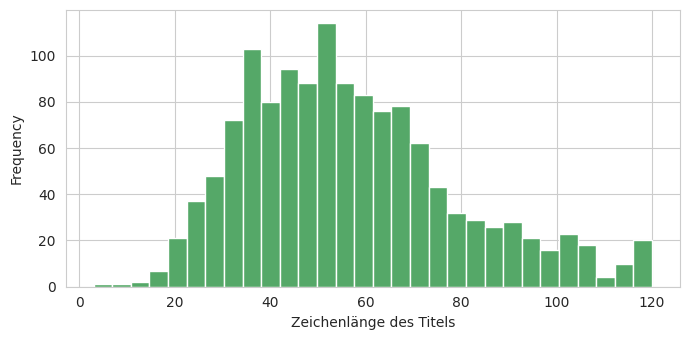

In [29]:
title_len = df["title"].astype(str).str.len()
print(title_len.describe())
fig, ax = plt.subplots(figsize=(7,3.5))
title_len.plot(kind="hist", bins=30, ax=ax, color="#55A868")
ax.set_xlabel("Zeichenlänge des Titels")
plt.tight_layout()
plt.show()


### 10.2 Häufigste Wörter (nach einfacher Tokenisierung)

In [30]:
from collections import Counter
stopwords = {"the","a","an","for","and","or","of","to","in","on","at","with","is","-","","$","%"}
tokens = []
for t in df["title"].dropna():
    tokens += [w.lower() for w in re.findall(r"[A-Za-zÀ-ÿ]+", str(t)) if w.lower() not in stopwords and len(w) > 2]
top_words = Counter(tokens).most_common(20)
pd.DataFrame(top_words, columns=["Wort", "Häufigkeit"])


,Wort,Häufigkeit
0,off,181
1,ymmv,112
2,free,108
3,pack,52
4,only,47
5,sale,44
6,july,43
7,set,38
8,pro,38
9,wireless,38


## 11. Zusammenfassung und Vergleich mit dem Rohdatensatz

In [31]:
print("="*70)
print("ZUSAMMENFASSUNG: REFERENZDATENSATZ (rfd_main_cleaned.csv)")
print("="*70)
print(f"Datensatzgröße:              {df.shape[0]} Zeilen x {df.shape[1]} Spalten")
print()
print("Fehlende Werte (Top 3):")
for col, pct in missing['fehlend (%)'].head(3).items():
    print(f"  - {col:20s}: {pct:.1f}%")
print()
print(f"Exakte Duplikate (ganze Zeile): {n_exact_dupes}")
print(f"Duplikate nach identischer URL: {dup_checks['identische URL (url, ohne NaN)']}")
print()
print(f"parent_category: {df['parent_category'].nunique()} eindeutige Werte, {df['parent_category'].isna().sum()} fehlend")
print(f"thread_category: {df['thread_category'].nunique()} eindeutige Werte, {df['thread_category'].isna().sum()} fehlend")
print(f"source:          {df['source'].nunique()} eindeutige Werte, {df['source'].isna().sum()} fehlend")
print()
print(f"price/saving bereits numerisch: {pd.api.types.is_numeric_dtype(df['price'])} / {pd.api.types.is_numeric_dtype(df['saving'])}")
print(f"Mehrdeutige thread_category-Werte (>1 parent_category): {(mapping_counts > 1).sum()} von {mapping_counts.shape[0]}")
print("="*70)
print()
print("VERGLEICH ZUM ROHDATENSATZ (rfd_main.csv, aus EDA_Datenexploration.ipynb):")
print("- Formatierungsfehler (price/saving): BEHOBEN (jetzt numerisch)")
print("- Fehlende Werte: NICHT durchgängig behoben (saving sogar leicht höherer Anteil fehlend)")
print("- Duplikate: NICHT behoben (URL-Duplikate praktisch unverändert)")
print("- Semantische Heterogenität: NICHT behoben (parent_category/thread_category unverändert)")
print("="*70)


ZUSAMMENFASSUNG: REFERENZDATENSATZ (rfd_main_cleaned.csv)
Datensatzgröße:              1325 Zeilen x 15 Spalten

Fehlende Werte (Top 3):
  - expiry              : 72.1%
  - saving              : 61.4%
  - parent_category     : 37.7%

Exakte Duplikate (ganze Zeile): 0
Duplikate nach identischer URL: 50

parent_category: 12 eindeutige Werte, 500 fehlend
thread_category: 55 eindeutige Werte, 0 fehlend
source:          280 eindeutige Werte, 63 fehlend

price/saving bereits numerisch: True / True
Mehrdeutige thread_category-Werte (>1 parent_category): 1 von 42

VERGLEICH ZUM ROHDATENSATZ (rfd_main.csv, aus EDA_Datenexploration.ipynb):
- Formatierungsfehler (price/saving): BEHOBEN (jetzt numerisch)
- Fehlende Werte: NICHT durchgängig behoben (saving sogar leicht höherer Anteil fehlend)
- Duplikate: NICHT behoben (URL-Duplikate praktisch unverändert)
- Semantische Heterogenität: NICHT behoben (parent_category/thread_category unverändert)


**Fazit:** Die Analyse des Referenzdatensatzes bestätigt die in Abschnitt 3.2 der
Arbeit getroffene Einschätzung: Die vorgenommene Bereinigung ist selektiv. Sie behebt
gezielt Formatierungsfehler bei `price` und `saving`, lässt die übrigen drei
Fehlerarten (Duplikate, fehlende Werte, semantische Heterogenität) jedoch nahezu
unangetastet. Der Referenzdatensatz eignet sich damit nur für die Bewertung von
Formatierungsfehlern als grober Vergleichspunkt, nicht jedoch für die anderen drei
Fehlerarten.